# Rerun: Beer Game with continuation scoring

**A fresh four-group game, using GPT-5.4 nano with low/medium reasoning.**

- Orders are integers **0–40 units per role per week**, enforced by the API schema and simulator. No order is clipped or replaced by code.
- This is a **modified Beer Game**. The researcher-selected limit is ten times initial demand (4), five times later customer demand (8); these future demand values are not disclosed in agent prompts. This choice prevents catastrophic scales but is not an empirically established human limit.
- Four conditions: control/trained × low/medium reasoning. Both receive identical game rules; only the training lesson differs. H2_API is not human 60/120-second time pressure.
- Four roles/group × 36 weeks; initial stock 12, flow 4; costs 0.50 held + 1.00 backlogged per unit/week. No revenue or factory fee.
- Zero remains legal. No instruction forces a positive order, specific beta, or treatment effect.
- Correctness retries, whole-group replacements, paced calls, cooldown, and checkpoints are retained. First-attempt reliability and boundary behavior remain visible.
- Beta fitting accounts for the order limit. At least 8 interior observations per role are required by the new numerical check. This does not guarantee identification.

**Use this notebook for the fresh rerun. Keep the earlier notebook/results as historical evidence.** The default is one complete group per condition (16 agents); that reruns all four games, not a powered hypothesis test. Do not spend the rest of your $3 on a larger sample until measurement is useful.

**Updated scoring:** after 36 agent weeks, 36 automatic weeks carry all inventory, backlog and outstanding orders forward. Total team cost includes both phases. The automatic phase costs no API calls and is excluded from beta estimation. This is a disclosed finite continuation, not a claim of optimal infinite-horizon scoring.

**New comprehension checks:** recurring backlog costs, delayed effects of orders, and whether continuation costs count. Passing does not establish good strategy.


In [1]:
from pathlib import Path
import sys, importlib, os, getpass
from IPython.display import display, Markdown, Image
BASE = Path.cwd()
if (BASE / "Project" / "beer_game_experiment").is_dir():
    BASE = BASE / "Project" / "beer_game_experiment"
elif (BASE / "beer_game_experiment").is_dir():
    BASE = BASE / "beer_game_experiment"
if not (BASE / "bounded_experiment.py").exists():
    raise FileNotFoundError("Open this notebook in beer_game_experiment.")
sys.path.insert(0, str(BASE))
import bounded_experiment as study
importlib.reload(study)


<module 'bounded_experiment' from '/Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/bounded_experiment.py'>

## Prepared settings

The $0.75 allowance includes failed requests and reservations. Completion is not guaranteed within it. Published GPT-5.4 nano prices are $0.20 input / $0.02 cached input / $1.25 output per million tokens. Actual cost with low/medium effort is unmeasured. [Official model documentation](https://developers.openai.com/api/docs/models/gpt-5.4-nano).

Do not change `GROUPS_PER_CELL` merely to seek significance. Keep the same settings to reuse this new run's cache. Old model/protocol replies cannot be reused here.


In [2]:
MODE = "offline"                 # "offline" = free software check
GROUPS_PER_CELL = 1
WEEKS = 36
BUDGET_USD = 0.75
REPLICATE_ID = "continuation-54nano-02"
CONFIG = dict(mode=MODE, stage="game", model=study.MODEL,
    groups_per_cell=GROUPS_PER_CELL, weeks=WEEKS, replicate_id=REPLICATE_ID,
    seed=20260928, budget_usd=BUDGET_USD, max_output_tokens=8192, timeout_s=300,
    max_concurrent_requests=4, effort_levels=study.EFFORT_LEVELS, order_limit=study.MAX_ORDER,
    continuation_weeks=study.CONTINUATION_WEEKS,
    max_attempts=3, max_group_replacements=3, max_transport_retries=5,
    request_interval_s=3.0, retry_backoff_s=5.0)
print("Model:", study.MODEL, "| effort:", study.EFFORT_LEVELS)
print("Order limit:", study.MAX_ORDER, "| mode:", MODE)
print(f"{GROUPS_PER_CELL*4} target groups / {GROUPS_PER_CELL*16} agents / {WEEKS} weeks")
print(f"{4+GROUPS_PER_CELL*16*(1+WEEKS)} planned requests, plus retries/replacements")
print(f"Allowance: ${BUDGET_USD:.2f}. Request starts paced at 3 seconds; cooldown may add time.")


Model: gpt-5.4-nano-2026-03-17 | effort: ('low', 'medium')
Order limit: 40 | mode: offline
4 target groups / 16 agents / 36 weeks
596 planned requests, plus retries/replacements
Allowance: $0.75. Request starts paced at 3 seconds; cooldown may add time.


## Free measurement checks

Includes recovery of a known beta under the 40-unit cap. Passing validates the software, not GPT behavior.

Also checks that final orders affect the score and that always-zero/always-maximum policies are not rewarded over a simple benchmark. These benchmarks are software checks, not optimal policies or agent instructions.

In [3]:
checks = study.measurement_self_check()
display(checks)
assert checks.passed.all(), "Measurement self-check failed; stop before paid calls."

display(study.economic_self_check())
print("Economic checks passed: final orders affect the score; boundary policies are not automatically optimal.")

,case,true_beta,estimated_beta,usable,passed
0,known beta 0.0,0.00,4.744894e-07,True,True
1,known beta 0.3,0.30,3.000000e-01,True,True
2,known beta 0.65,0.65,6.500000e-01,True,True
3,known beta 1.0,1.00,1.000000e+00,True,True
4,bounded known beta 0.65,0.65,6.500000e-01,True,True
5,copy demand: beta must be unidentified,NaN,NaN,False,True


,policy,agent_phase_cost,continuation_cost,scored_total_cost
0,0,5052.0,10916.0,15968.0
1,copy_demand,156.0,0.0,156.0
2,40,18444.0,23344.0,41788.0


Economic checks passed: final orders affect the score; boundary policies are not automatically optimal.


## Run all four games

This is the only paid cell in API mode. Allow up to two correctness retries; then replace a failed group, at most three replacements per target. Temporary API errors use up to five transport retries. Billing/quota errors stop. All costs stay within the local reservation guard; no guarantee this buys every game. No new model, larger sample or extra budget is selected automatically.

The first four ordering checks and each group's four rules checks validate response format and readbacks. They do not prove realistic strategic behavior. The final report assesses that separately.


In [4]:
client = None
results = None
run_dir = study.latest_run(BASE, CONFIG)
try:
    if MODE == "api":
        from openai import AsyncOpenAI
        key = os.environ.get("OPENAI_API_KEY") or getpass.getpass("OpenAI API key (hidden): ")
        if not key.strip():
            raise ValueError("An API key is required in API mode.")
        client = AsyncOpenAI(api_key=key.strip(), max_retries=0, timeout=CONFIG["timeout_s"])
        del key
    results, run_dir = await study.run_study(BASE, CONFIG, client=client)
    print("Games complete. Read the report before scaling.")
except study.ExperimentStopped as exc:
    print(str(exc))
    print("Run the report cell to inspect the saved status.")
finally:
    if client is not None:
        await client.close()
    print("Results folder:", run_dir)


Games complete. Read the report before scaling.
Results folder: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/results/bounded_54nano_offline_48039ab517b106eb


## Results and readiness

Read the conclusions, performance, beta coverage, first-attempt reliability, and **zero-order / upper-limit rates**. More than 20% cap hits in a condition flags an overly binding limit for review; this threshold is a pilot design choice. Never discard completed games because they have an undesirable result. A valid rerun can still fail to identify beta or support H1/H2. Replacement selection prevents confirmatory p-values.

Read `scored_team_costs.csv` for the full objective (agent costs + continuation costs), and `automatic_continuation.csv` for every automatic round. Other performance charts and beta describe agent weeks only.

# Budget verification — conclusions

1. OFFLINE SOFTWARE CHECK ONLY: not GPT behavior.
2. Run completed: 596 successful responses; 0 saved failed/pending requests.
3. Ordering checks across conditions: 4/4 passed. Recorded estimated charges/reservations: $0.0000; allowance $0.75.
4. This modified game limits weekly orders to 0–40; H2_API compares low/medium reasoning, not human time pressure. Completion alone does not establish H1/H2.

Retries: 0 failed attempts later recovered; 0 failed/pending attempts remain unresolved. All attempt costs are included.
The protocol permits at most two retries for incorrect observation/rules replies, using the same model and effort. Separately, bounded transport retries handle temporary service errors without changing prompts. No desired order, beta, or hypothesis result is supplied. Results describe agents with this retry policy; retries add resources and may differ by condition.

## First-attempt reliability

```
                first_attempt_requests  first_attempt_valid  first_attempt_valid_rate
trained effort                                                                       
False   low                        149                  149                       1.0
        medium                     149                  149                       1.0
True    low                        149                  149                       1.0
        medium                     149                  149                       1.0
```
These checks measure rules answers and accurate copying of observations. Passing does not prove optimal ordering, understanding of delays, or identifiable beta. Retries can conceal a weak first-attempt rate, so inspect this table before scaling.

## Retry counts by condition

```
                attempts  logical_requests  recovered_failed_attempts  extra_attempts
trained effort                                                                       
False   low          149               149                          0               0
        medium       149               149                          0               0
True    low          149               149                          0               0
        medium       149               149                          0               0
```

Group collection: 4/4 required groups completed; 0 failed groups retained in the audit.
Completed-group performance and beta exclude failed partial games. all_candidate_rows.csv retains committed rounds from all candidates; individual request files retain uncommitted replies. Replacement is based only on exhausted correctness failures, never beta or effect direction. Replacing failures selects for successful responders; confirmatory H1/H2 p-values are withheld if replacement occurred.

## Scored objective: agent phase plus automatic continuation

```
           group_id  trained effort  agent_phase_cost  continuation_cost  scored_total_cost  continuation_weeks  end_inventory  end_backlog  end_supply_line
   b000_control_low    False    low             910.5              919.0             1829.5                  36             51            0               96
b000_control_medium    False medium             896.5              981.5             1878.0                  36             55            0               96
   b000_trained_low     True    low             907.0              831.5             1738.5                  36             45            0               96
b000_trained_medium     True medium             919.0              952.5             1871.5                  36             52            0               96
```
Lower scored_total_cost is better. Automatic continuation is a fixed 36-week evaluation with no API calls; it is not GPT behavior and is excluded from beta, fulfillment and boundary statistics below. Existing performance charts show the agent phase only. This finite continuation is a protocol choice, not an infinite-horizon optimum. Residual inventory, backlog and supply line are reported for review.

## Order-boundary audit

```
                decisions  zero_rate  cap_hit_rate  max_order
trained effort                                               
False   low           144      0.021           0.0         20
        medium        144      0.000           0.0         17
True    low           144      0.007           0.0         18
        medium        144      0.021           0.0         26
```
The cap prevents million-unit orders mechanically. It does not prove realistic behavior. Beta predictions are capped at the same limit; fewer than 8 strictly interior orders per role makes beta unusable. A cap-hit rate above 20% in any condition is a prespecified pilot warning, not a significance filter. High zero rates remain visible; zero orders never trigger replacement.
5. 16/16 roles and 4/4 groups have usable beta.
6. Zero orders: 1.2%; 0/16 roles copied demand for every week.
7. Offline check only; live model behavior is unverified.

## Supply-chain performance

```
 trained effort  groups  mean_team_cost  median_team_cost  min_team_cost  max_team_cost  mean_backlog_cost  mean_customer_fulfillment
   False    low       1           910.5             910.5          910.5          910.5               32.0                        1.0
   False medium       1           896.5             896.5          896.5          896.5                8.0                        1.0
    True    low       1           907.0             907.0          907.0          907.0                3.0                        1.0
    True medium       1           919.0             919.0          919.0          919.0               18.0                        1.0
```

## Beta and reasons for unusable fits

```
                       agent_id  alpha  beta_for_interpretation  usable fit_flag
   b000_control_low_distributor 0.3932                   0.6424    True       ok
       b000_control_low_factory 0.3527                   0.7264    True       ok
      b000_control_low_retailer 0.4032                   0.4758    True       ok
    b000_control_low_wholesaler 0.3663                   0.5493    True       ok
b000_control_medium_distributor 0.4165                   0.7000    True       ok
    b000_control_medium_factory 0.3846                   0.7280    True       ok
   b000_control_medium_retailer 0.2518                   1.1182    True       ok
 b000_control_medium_wholesaler 0.3969                   0.6630    True       ok
   b000_trained_low_distributor 0.4329                   0.7293    True       ok
       b000_trained_low_factory 0.3582                   0.7222    True       ok
      b000_trained_low_retailer 0.3832                   0.6238    True       ok
    b000_trained_low_wholesaler 0.3233                   0.7094    True       ok
b000_trained_medium_distributor 0.5017                   0.6860    True       ok
    b000_trained_medium_factory 0.3671                   0.6925    True       ok
   b000_trained_medium_retailer 0.5146                   0.6667    True       ok
 b000_trained_medium_wholesaler 0.4520                   0.6009    True       ok
```

Standard scoring: 0.50 per held unit/week + 1.00 per backlogged unit/week; no sales revenue or production fee. Four roles, local information, 12 initial units per role; external demand 4 in weeks 1–4 and 8 afterward. Free choices start in week 1; this is a bounded-order variant with a 40-unit weekly order limit, not an unrestricted standard Beer Game. H2_API concerns reasoning effort; it cannot establish human time-pressure effects.

A useful verification result means complete responses, measurable beta, interpretable performance, and affordable token use. It does NOT mean the treatment effect has the predicted sign.


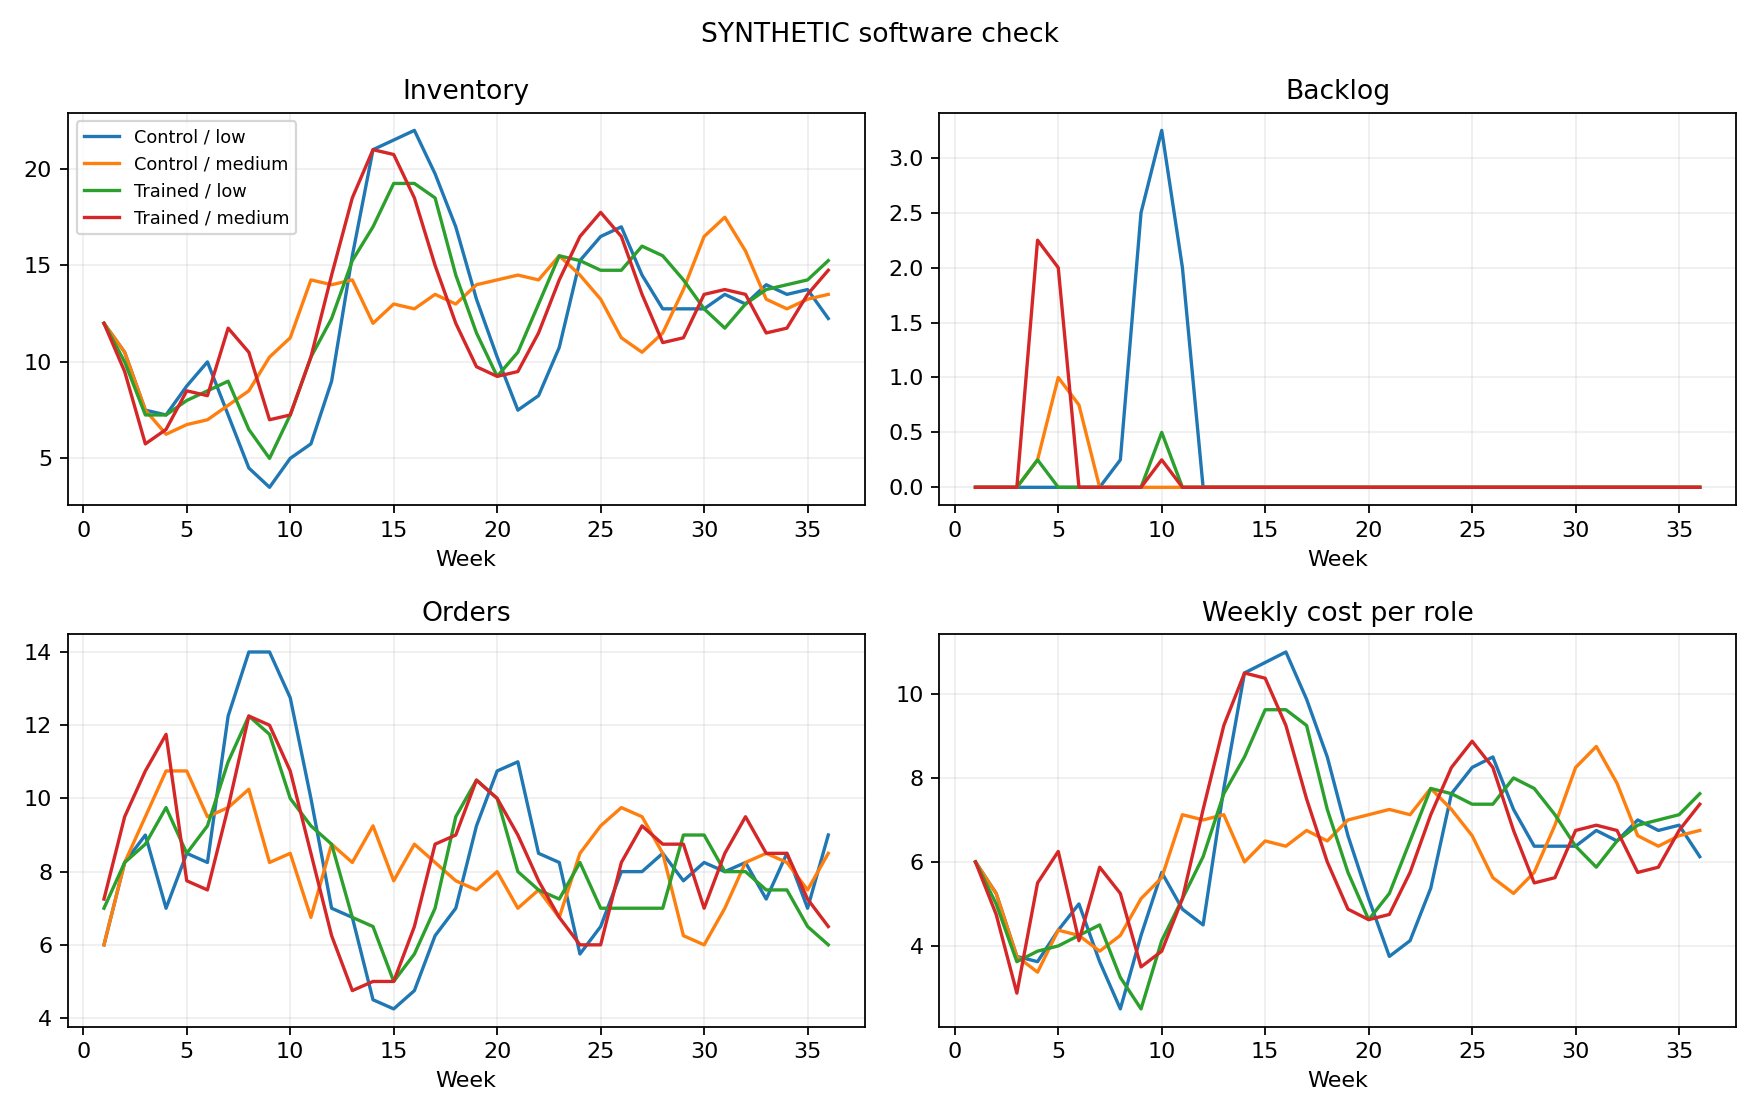

Report: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/results/bounded_54nano_offline_48039ab517b106eb/VERIFICATION_REPORT.md


In [5]:
if (run_dir / "progress.json").exists():
    display(Markdown(study.verification_report(run_dir, CONFIG)))
    figure = run_dir / "supply_chain_performance.png"
    if figure.exists():
        display(Image(filename=str(figure)))
    print("Report:", run_dir / "VERIFICATION_REPORT.md")
else:
    print("No run records yet.")
